In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from numba import njit, prange
import math
from scipy import ndimage as ndi
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap

In [2]:
@njit
def sigmoid(z):
    # Численно устойчивая сигмоида
    if z > 40.0:
        return 1.0
    elif z < -40.0:
        return 0.0
    else:
        return 1.0 / (1.0 + math.exp(-z))
    # return 1.0 / (1.0 + math.exp(-z))

@njit
def calculate_point(
    rs, ra, xc, N, x0,
    transient, tail_len, max_period,
    period_tol, extinction_tol, lyap_tol,
    escape_limit, escape_steps
):
    x = x0

    if x == 0.0:
        return 0

    # -----------------------------
    # Переходный процесс
    # -----------------------------
    for _ in range(transient):

        A = sigmoid(x - xc)
        B = 1.0 - A

        if N == 0.0:
            m = 1.0
        else:
            m = x / (N + x)

        q = B * ra + A * m * rs

        x = q * x

        if not math.isfinite(x) or x > escape_limit:
            return max_period + 2

        if x < extinction_tol:
            return 0

    # -----------------------------
    # Хвост траектории
    # -----------------------------
    tail = np.empty(tail_len)

    lyap_sum = 0.0

    for i in range(tail_len):

        A = sigmoid(x - xc)
        B = 1.0 - A

        if N == 0.0:
            m = 1.0
            mp = 0.0
        else:
            m = x / (N + x)
            mp = N / ((N + x) * (N + x))

        q = B * ra + A * m * rs

        # Производная q(x)
        qp = A * B * (m * rs - ra) + A * mp * rs

        # F'(x) = q(x) + x*q'(x)
        derivative = q + x * qp

        if abs(derivative) < 1e-300:
            derivative = 1e-300

        lyap_sum += math.log(abs(derivative))

        x = q * x
        tail[i] = x

        if not math.isfinite(x) or x > escape_limit:
            return max_period + 2

        if x < extinction_tol:
            return 0

    # -----------------------------
    # Проверка ухода в бесконечность
    # -----------------------------
    # if rs > 1.0 and tail[-1] > escape_limit / 100:
    # 
    #     increasing = True
    # 
    #     start = max(1, tail_len - escape_steps)
    # 
    #     for i in range(start, tail_len):
    #         if tail[i] <= tail[i - 1]:
    #             increasing = False
    #             break
    # 
    #     if increasing:
    #         return max_period + 2

    # -----------------------------
    # Проверка периодов
    # -----------------------------
    for p in range(1, max_period + 1):

        if 2 * p > tail_len:
            break

        error = 0.0
        scale = 1.0

        for i in range(tail_len - p, tail_len):

            diff = abs(tail[i] - tail[i - p])

            if diff > error:
                error = diff

            if abs(tail[i]) > scale:
                scale = abs(tail[i])

            if abs(tail[i - p]) > scale:
                scale = abs(tail[i - p])

        if error / scale < period_tol:
            return p

    # -----------------------------
    # Показатель Ляпунова
    # -----------------------------
    lyap = lyap_sum / tail_len

    if lyap > lyap_tol:
        return max_period + 1

    return max_period + 3

@njit(parallel=True)
def calculate_map(
    rs_values, ra_values,
    xc, N, x0,
    transient, tail_len, max_period,
    period_tol, extinction_tol, lyap_tol,
    escape_limit, escape_steps
):

    result = np.empty(
        (len(rs_values), len(ra_values)),
        dtype=np.int16
    )

    for i in prange(len(rs_values)):

        rs = rs_values[i]

        for j in range(len(ra_values)):

            ra = ra_values[j]

            result[i, j] = calculate_point(
                rs, ra, xc, N, x0,
                transient, tail_len, max_period,
                period_tol, extinction_tol, lyap_tol,
                escape_limit, escape_steps
            )

    return result


def dynamic_regime_map(
    xc,
    N,
    rs_range=(0, 10),
    ra_range=(0, 10),
    resolution=800,
    x0=1.0,
    transient=2000,
    tail_len=256,
    max_period=16,
    period_tol=1e-7,
    extinction_tol=1e-14,
    lyap_tol=1e-4,
    escape_limit=1e12,
    escape_steps=10,
    figsize=(4, 3),
    fontsize=14,
    ax=None,
    show=True
):

    if N < 0:
        raise ValueError("N должно быть >= 0")

    if x0 <= 0:
        raise ValueError("x0 должно быть > 0")

    rs_values = np.linspace(
        rs_range[0],
        rs_range[1],
        resolution
    )

    ra_values = np.linspace(
        ra_range[0],
        ra_range[1],
        resolution
    )

    tail_len = max(tail_len, 2 * max_period)

    result = calculate_map(
        rs_values,
        ra_values,
        xc, N, x0,
        transient,
        tail_len,
        max_period,
        period_tol,
        extinction_tol,
        lyap_tol,
        escape_limit,
        escape_steps
    )

    # ---------------------------------
    # Цвета
    # ---------------------------------

    colors = ["white"]

    period_colors = plt.cm.viridis(
        np.linspace(0.1, 0.9, max_period)
    )

    for c in period_colors:
        colors.append(c)

    colors.extend([
        "red",
        "black",
        "gray"
    ])

    cmap = ListedColormap(colors)

    n_categories = max_period + 4

    boundaries = np.arange(
        -0.5,
        n_categories + 0.5,
        1
    )

    norm = BoundaryNorm(
        boundaries,
        cmap.N
    )

    # ---------------------------------
    # Если ax не передан — создаём
    # ---------------------------------

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    # ---------------------------------
    # Рисуем карту
    # ---------------------------------

    im = ax.imshow(
        result,
        origin="lower",
        extent=[
            ra_range[0],
            ra_range[1],
            rs_range[0],
            rs_range[1]
        ],
        aspect="auto",
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    ax.set_xlabel(r"$r_a$", fontsize=fontsize-1)
    ax.set_ylabel(r"$r_s$", fontsize=fontsize-1)

    ax.set_title(
        rf"$x_c={xc},\ N={N}$",
        fontsize=fontsize
    )

    # ---------------------------------
    # Colorbar
    # ---------------------------------

    ticks = list(range(max_period + 4))

    labels = ["$x\\to0$"]

    for p in range(1, max_period + 1):
        labels.append(f"$p={p}$")

    labels.extend([
        "хаос",
        "$x\\to\\infty$",
        "> max period"
    ])

    cbar = fig.colorbar(
        im,
        ax=ax,
        ticks=ticks
    )

    cbar.ax.set_yticklabels(labels)
    cbar.ax.tick_params(labelsize=fontsize-2)

    if show:
        plt.tight_layout()
        plt.show()

    return fig, ax, result

In [69]:
def plot_regime_maps(
    params,
    rs_range=(0, 10),
    ra_range=(0, 10),
    resolution=400,
    x0=1.0,
    transient=5000,
    tail_len=128,
    max_period=16,
    period_tol=1e-7,
    extinction_tol=1e-12,
    lyap_tol=1e-4,
    escape_limit=1e12,
    escape_steps=10,
    figsize=None,
    fontsize=9,
    min_label_area=100
):
    """
    Строит карты динамических режимов в один горизонтальный ряд.

    params = [(xc1, N1), (xc2, N2), ...]

    По горизонтали: r_a
    По вертикали:   r_s

    Обозначения на картах:
        x -> 0  — вымирание;
        1, 2, ... — периодические циклы;
        C — хаос;
        U — убегание на бесконечность;
        p > max_period — период выше заданного предела.

    Количество элементов цикла указывается непосредственно
    на соответствующей области карты. Colorbar отсутствует.
    """

    n_maps = len(params)

    if n_maps == 0:
        raise ValueError("Необходимо передать хотя бы одну пару (xc, N)")

    if max_period < 1:
        raise ValueError("max_period должен быть >= 1")

    if min_label_area < 1:
        raise ValueError("min_label_area должен быть >= 1")

    if figsize is None:
        figsize = (4 * n_maps, 3.5)

    # -------------------------------------------------
    # Сетка параметров
    # -------------------------------------------------
    rs_values = np.linspace(
        rs_range[0],
        rs_range[1],
        resolution
    )

    ra_values = np.linspace(
        ra_range[0],
        ra_range[1],
        resolution
    )

    tail_len = max(tail_len, 2 * max_period)

    if x0 <= 0:
        raise ValueError("x0 должно быть > 0")

    # -------------------------------------------------
    # Расчёт карт динамических режимов
    # -------------------------------------------------
    results = []

    for xc, N in params:

        if N < 0:
            raise ValueError("N должно быть >= 0")

        result = calculate_map(
            rs_values,
            ra_values,
            xc,
            N,
            x0,
            transient,
            tail_len,
            max_period,
            period_tol,
            extinction_tol,
            lyap_tol,
            escape_limit,
            escape_steps
        )

        results.append(result)

    # -------------------------------------------------
    # Цвета динамических режимов
    # Коды сохраняются такими, какими их выдаёт calculate_map
    # -------------------------------------------------
    # -------------------------------------------------
    # Цвета динамических режимов
    # -------------------------------------------------
    
    # Вымирание
    base_colors = ["#F8F7F2"]
    
    # Чередование холодных и тёплых оттенков.
    # Индекс в списке соответствует периоду цикла.
    period_colors = [
        "#527FA5",  # 1 — холодный синий
        "#D99A67",  # 2 — тёплый охристый
        "#E8B982",  # 3 — светло-синий
        "#C97B55",  # 4 — терракотовый
        "#6F9FBE",  # 5 — голубой
        "#6fabc5",  # 6 — песочный
        "#405F87",  # 7 — глубокий синий
        "#F2D2A9",  # 8 — светлый тёплый
        "#6b87b5",  # 9 — серо-голубой
        "#D6A17B",  # 10 — приглушённый персиковый
        "#5d8296",  # 11 — стальной голубой
        "#e0a375",  # 12 — мягкий абрикосовый
        "#5f8099",  # 13 — сине-серый
        "#D2A078",  # 14 — тёплый бежево-коричневый
        "#A6C8D9",  # 15 — светлый холодный
        "#B97958",  # 16 — приглушённая терракота
    ]
    
    # Если max_period больше 16, продолжаем чередование
    # цветов автоматически.
    while len(period_colors) < max_period:
        period_colors.append(
            "#7195A9" if len(period_colors) % 2 == 0
            else "#D6A17B"
        )
    
    base_colors.extend(period_colors[:max_period])
    
    base_colors.extend([
        # "#AEB4BC",  # хаос — серый
        "#bcaeae",
        "#D65347",  # убегание — коралловый
        "#DCE3EA"   # период > max_period
    ])
    
    cmap = ListedColormap(base_colors)

    boundaries = np.arange(
        -0.5,
        max_period + 4.5,
        1
    )

    norm = BoundaryNorm(
        boundaries,
        cmap.N
    )

    # -------------------------------------------------
    # Функция нанесения подписей непосредственно на карту
    # -------------------------------------------------
    def add_region_labels(ax, result):

        regimes = [
            (0, r"$x\to0$", "#626A73"),
        ]

        # Периодические циклы: подпись числом
        for period in range(1, max_period + 1):
            regimes.append(
                (period, str(period), "#343943")
            )

        # Хаос
        regimes.append(
            (max_period + 1, "C", "#626A73")
        )

        # Убегание на бесконечность
        regimes.append(
            (max_period + 2, "U", "#7A2E16")
        )

        # Период выше заданного предела
        regimes.append(
            (max_period + 3, "", "#596574")
        )

        height, width = result.shape

        for code, label, text_color in regimes:

            mask = result == code

            if not np.any(mask):
                continue
            
            # Выделяем связные области одного режима.
            # Соседство по диагонали тоже учитывается.
            components, n_components = ndi.label(
                mask,
                structure=np.ones((3, 3), dtype=np.uint8)
            )

            if n_components == 0:
                continue

            slices = ndi.find_objects(components)
            component_info = []

            for component_id, slc in enumerate(slices, start=1):

                if slc is None:
                    continue

                local_component = (
                    components[slc] == component_id
                )

                area = int(local_component.sum())

                component_info.append(
                    (area, component_id, slc, local_component)
                )

            # Крупные области подписываем все.
            # Если область режима слишком мала, подписываем
            # хотя бы самую крупную из его областей.
            selected = [
                item for item in component_info
                if item[0] >= min_label_area
            ]

            # if not selected and component_info:
            #     selected = [
            #         max(component_info, key=lambda item: item[0])
            #     ]

            for area, component_id, slc, local_component in selected:

                # Выбираем точку в глубине области, чтобы подпись
                # не оказалась на границе двух режимов.
                padded = np.pad(
                    local_component,
                    1,
                    mode="constant",
                    constant_values=False
                )

                distances = ndi.distance_transform_edt(padded)

                row, col = np.unravel_index(
                    np.argmax(distances),
                    distances.shape
                )

                row = row - 1 + slc[0].start
                col = col - 1 + slc[1].start

                # Перевод индексов матрицы в координаты параметров
                ra = (
                    ra_range[0]
                    + (col + 0.5) * (ra_range[1] - ra_range[0]) / width
                )

                rs = (
                    rs_range[0]
                    + (row + 0.5) * (rs_range[1] - rs_range[0]) / height
                )

                label_size = (
                    max(7, fontsize - 6)
                    if code == max_period + 3
                    else max(7, fontsize - 6)
                )

                ax.text(
                    ra,
                    rs,
                    label,
                    ha="center",
                    va="center",
                    fontsize=label_size,
                    # color=text_color,
                    color="black",
                    zorder=5,
                    bbox=dict(
                        boxstyle="square,pad=0.5",  # pad=2.0 задает большое пустое пространство вокруг
                        facecolor="none",           # Делаем фон прозрачным
                        edgecolor="none"            # Делаем границы рамки невидимыми
                    ),
                    path_effects=[
                        pe.withStroke(
                            linewidth=0.5,
                            foreground="#F8F7F2"
                        ),
                        pe.Normal()
                    ]
            
                )

    # -------------------------------------------------
    # Построение карт
    # -------------------------------------------------
    fig = plt.figure(
        figsize=figsize,
        constrained_layout=True
    )

    gs = fig.add_gridspec(
        1,
        n_maps,
        wspace=0.12
    )

    axes = [
        fig.add_subplot(gs[0, i])
        for i in range(n_maps)
    ]

    for ax, result, (xc, N) in zip(
        axes,
        results,
        params
    ):

        ax.imshow(
            result,
            origin="lower",
            extent=[
                ra_range[0],
                ra_range[1],
                rs_range[0],
                rs_range[1]
            ],
            aspect="auto",
            cmap=cmap,
            norm=norm,
            interpolation="nearest"
        )

        # Подписи периодов и остальных режимов
        add_region_labels(ax, result)

        ax.set_xlabel(
            r"$r_a$",
            fontsize=fontsize
        )

        ax.set_ylabel(
            r"$r_s$",
            fontsize=fontsize
        )

        ax.set_title(
            rf"$x_c={xc},\ N={N}, x_0={x0}$",
            fontsize=fontsize
        )

        ax.tick_params(
            labelsize=max(6, fontsize - 2)
        )

    # Colorbar намеренно отсутствует

    return fig, axes, results

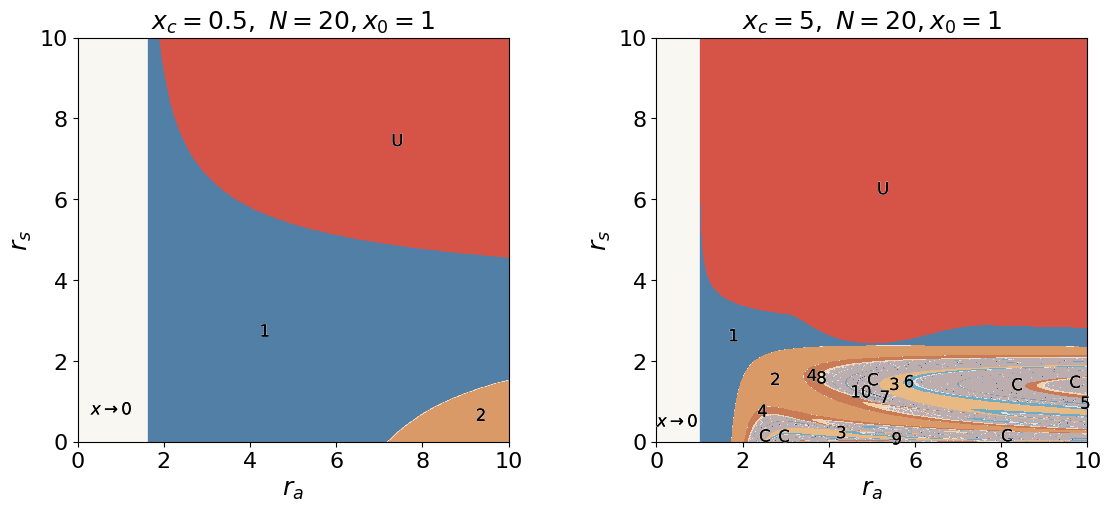

In [60]:
params = [
    (0.5, 20),
    (5, 20),
]
resolution = 1300
fig, axes, results = plot_regime_maps(
    params=params,
    x0=1,
    rs_range=(0, 10),
    ra_range=(0, 10),
    resolution=resolution,
    transient=2000,
    tail_len=512,
    max_period=10,
    figsize=(11, 5),
    fontsize=18, 
    min_label_area=round(200 * (resolution / 300) ** 2)
)

plt.show()

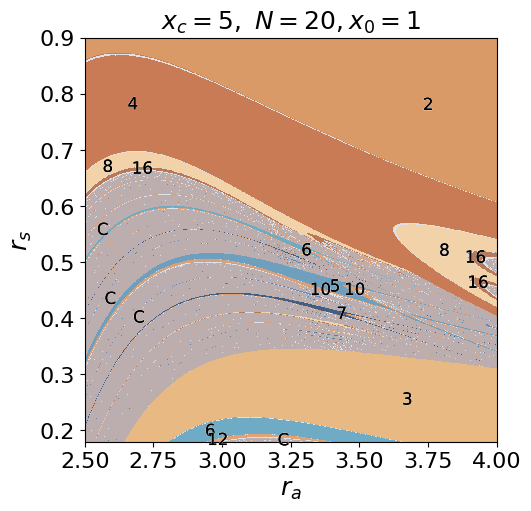

In [75]:
resolution = 1300

fig, axes, results = plot_regime_maps(
    params=[(5, 20)],
    x0=1,
    rs_range=(0.18, 0.9),
    ra_range=(2.5, 4),
    resolution=resolution,
    transient=2000,
    tail_len=512,
    max_period=16,
    figsize=(5.2, 5),
    fontsize=18,
    # min_label_area=100
    min_label_area=round(100 * (resolution / 300) ** 2)
)
plt.show()

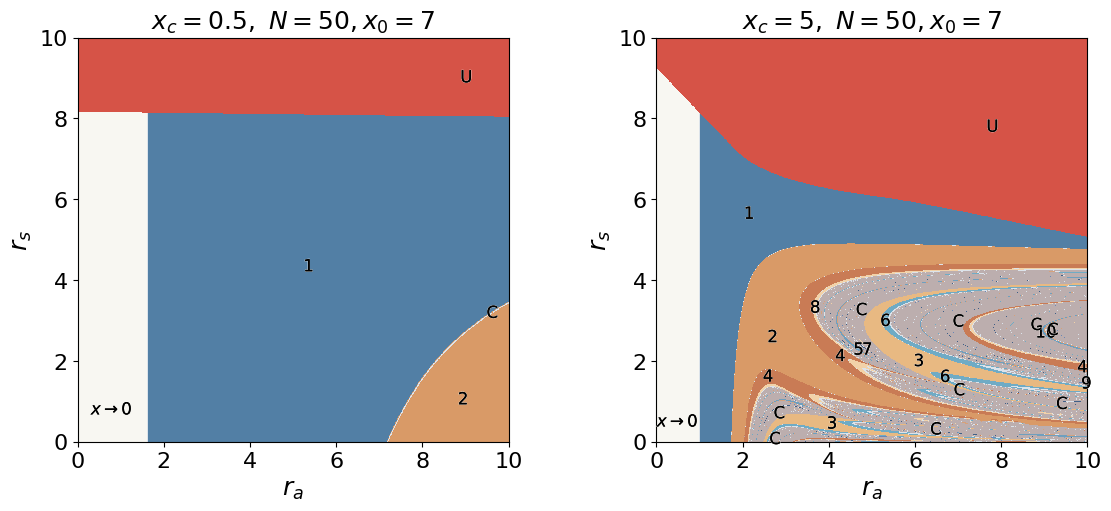

In [61]:
params = [
    (0.5, 50),
    (5, 50),
]

fig, axes, results = plot_regime_maps(
    params=params,
    x0=7,
    rs_range=(0, 10),
    ra_range=(0, 10),
    resolution=1300,
    transient=2000,
    tail_len=512,
    max_period=10,
    figsize=(11, 5),
    fontsize=18,
    min_label_area=5000
)

plt.show()

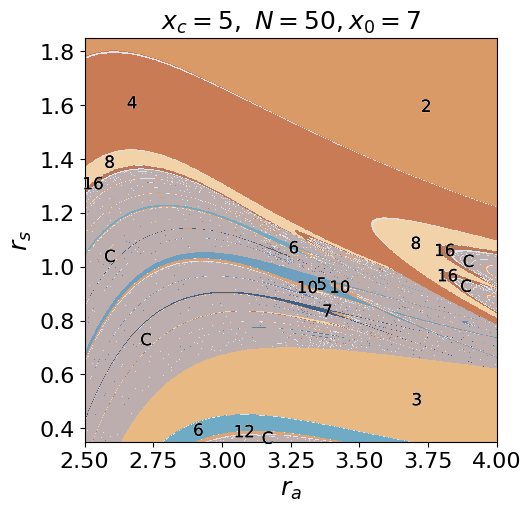

In [77]:
resolution = 1300

fig, axes, results = plot_regime_maps(
    params=[(5, 50)],
    x0=7,
    rs_range=(0.35, 1.85),
    ra_range=(2.5, 4),
    resolution=resolution,
    transient=2000,
    tail_len=512,
    max_period=16,
    figsize=(5.2, 5),
    fontsize=18,
    # min_label_area=100
    min_label_area=round(100 * (resolution / 300) ** 2)
)

plt.show()

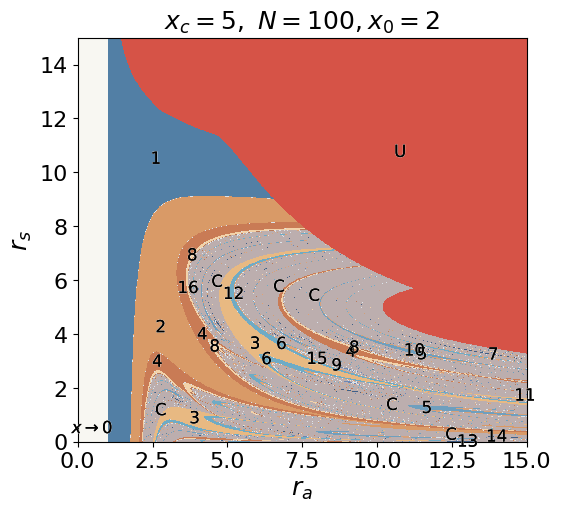

In [63]:
params = [
    (5, 100),
]
resolution=1300
fig, axes, results = plot_regime_maps(
    params=params,
    x0=2,
    rs_range=(0, 15),
    ra_range=(0, 15),
    resolution=resolution,
    transient=2000,
    tail_len=512,
    max_period=16,
    figsize=(5.5, 5),
    fontsize=18,
    min_label_area=round(120 * (resolution / 300) ** 2)
)

plt.show()

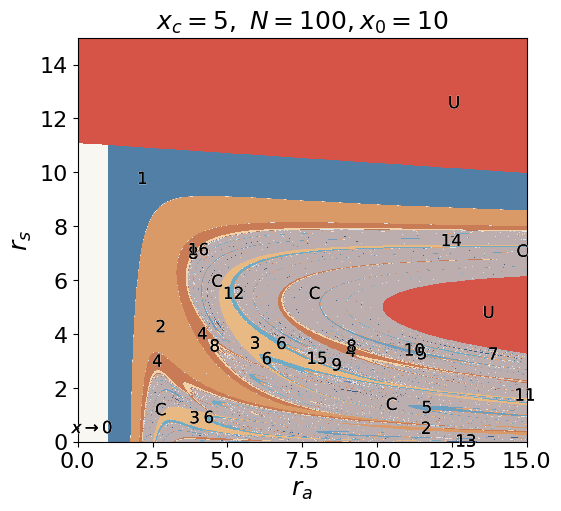

In [64]:
params = [
    (5, 100),
]
resolution=1300
fig, axes, results = plot_regime_maps(
    params=params,
    x0=10,
    rs_range=(0, 15),
    ra_range=(0, 15),
    resolution=resolution,
    transient=2000,
    tail_len=512,
    max_period=16,
    figsize=(5.5, 5),
    fontsize=18,
    min_label_area=round(100 * (resolution / 300) ** 2)
)

plt.show()

In [83]:
@njit(parallel=True)
def calculate_map_2(
    xc_values, N_values,
    rs, ra, x0,
    transient, tail_len, max_period,
    period_tol, extinction_tol, lyap_tol,
    escape_limit, escape_steps
):
    result = np.empty(
        (len(N_values), len(xc_values)),
        dtype=np.int16
    )

    for i in prange(len(N_values)):

        N = N_values[i]

        for j in range(len(xc_values)):

            xc = xc_values[j]

            result[i, j] = calculate_point(
                rs, ra, xc, N, x0,
                transient, tail_len, max_period,
                period_tol, extinction_tol, lyap_tol,
                escape_limit, escape_steps
            )

    return result

def plot_regime_maps_2(
    params,
    xc_range=(0, 10),
    N_range=(0, 10),
    resolution=400,
    x0=1.0,
    transient=5000,
    tail_len=128,
    max_period=16,
    period_tol=1e-7,
    extinction_tol=1e-8,
    lyap_tol=1e-4,
    escape_limit=1e12,
    escape_steps=10,
    figsize=None,
    fontsize=9,
    min_label_area=100
):
    """
    Строит карты динамических режимов в один горизонтальный ряд.

    params = [(rs1, ra1), (rs2, ra2), ...]

    По горизонтали: x_c
    По вертикали:   N

    Обозначения:
        x -> 0  — вымирание;
        1, 2, ... — периодические циклы;
        C — хаос;
        U — убегание на бесконечность.
    """

    n_maps = len(params)

    if n_maps == 0:
        raise ValueError(
            "Необходимо передать хотя бы одну пару (rs, ra)"
        )

    if max_period < 1:
        raise ValueError("max_period должен быть >= 1")

    if min_label_area < 1:
        raise ValueError("min_label_area должен быть >= 1")

    if resolution < 2:
        raise ValueError("resolution должен быть >= 2")

    if N_range[0] < 0:
        raise ValueError("N должен быть >= 0")

    if N_range[0] >= N_range[1]:
        raise ValueError("N_range задан некорректно")

    if xc_range[0] >= xc_range[1]:
        raise ValueError("xc_range задан некорректно")

    if figsize is None:
        figsize = (4 * n_maps, 3.5)

    # -------------------------------------------------
    # Сетка параметров
    # -------------------------------------------------
    xc_values = np.linspace(
        xc_range[0],
        xc_range[1],
        resolution
    )

    N_values = np.linspace(
        N_range[0],
        N_range[1],
        resolution
    )

    tail_len = max(tail_len, 2 * max_period)

    if x0 <= 0:
        raise ValueError("x0 должно быть > 0")

    # -------------------------------------------------
    # Расчёт карт динамических режимов
    # -------------------------------------------------
    results = []

    for rs, ra in params:

        result = calculate_map_2(
            xc_values,
            N_values,
            rs,
            ra,
            x0,
            transient,
            tail_len,
            max_period,
            period_tol,
            extinction_tol,
            lyap_tol,
            escape_limit,
            escape_steps
        )

        results.append(result)

    # -------------------------------------------------
    # Цвета динамических режимов
    # -------------------------------------------------

    # Вымирание
    base_colors = ["#F8F7F2"]

    # Чередование холодных и тёплых оттенков.
    # Индекс соответствует периоду цикла.
    period_colors = [
        "#527FA5",  # 1 — холодный синий
        "#D99A67",  # 2 — тёплый охристый
        "#E8B982",  # 3 — светло-синий
        "#C97B55",  # 4 — терракотовый
        "#6F9FBE",  # 5 — голубой
        "#6fabc5",  # 6 — песочный
        "#405F87",  # 7 — глубокий синий
        "#F2D2A9",  # 8 — светлый тёплый
        "#6b87b5",  # 9 — серо-голубой
        "#D6A17B",  # 10 — приглушённый персиковый
        "#5d8296",  # 11 — стальной голубой
        "#e0a375",  # 12 — мягкий абрикосовый
        "#5f8099",  # 13 — сине-серый
        "#D2A078",  # 14 — тёплый бежево-коричневый
        "#A6C8D9",  # 15 — светлый холодный
        "#B97958",  # 16 — приглушённая терракота
    ]

    # Если max_period больше 16, продолжаем чередование.
    while len(period_colors) < max_period:
        period_colors.append(
            "#7195A9" if len(period_colors) % 2 == 0
            else "#D6A17B"
        )

    base_colors.extend(period_colors[:max_period])

    base_colors.extend([
        "#bcaeae",  # Хаос
        "#D65347",  # Убегание
        "#DCE3EA"   # Период > max_period
    ])

    cmap = ListedColormap(base_colors)

    boundaries = np.arange(
        -0.5,
        max_period + 4.5,
        1
    )

    norm = BoundaryNorm(
        boundaries,
        cmap.N
    )

    # -------------------------------------------------
    # Подписи динамических режимов
    # -------------------------------------------------
    def add_region_labels(ax, result):

        regimes = [
            (0, r"$x\to0$", "#626A73")
        ]

        # Периодические циклы
        for period in range(1, max_period + 1):
            regimes.append(
                (period, str(period), "#343943")
            )

        # Хаос
        regimes.append(
            (max_period + 1, "C", "#626A73")
        )

        # Убегание на бесконечность
        regimes.append(
            (max_period + 2, "U", "#7A2E16")
        )
        
        # Период выше заданного предела
        regimes.append(
            (max_period + 3, "", "#596574")
        )

        height, width = result.shape

        for code, label, text_color in regimes:

            mask = result == code

            if not np.any(mask):
                continue

            # Выделяем связные области одного режима.
            # Соседство по диагонали тоже учитывается.
            components, n_components = ndi.label(
                mask,
                structure=np.ones((3, 3), dtype=np.uint8)
            )

            if n_components == 0:
                continue

            slices = ndi.find_objects(components)
            component_info = []

            for component_id, slc in enumerate(
                slices, start=1
            ):

                if slc is None:
                    continue

                local_component = (
                    components[slc] == component_id
                )

                area = int(local_component.sum())

                component_info.append(
                    (area, component_id, slc, local_component)
                )

            # Подписываем все достаточно крупные области.
            # Если таких нет, подписываем крупнейшую.
            selected = [
                item for item in component_info
                if item[0] >= min_label_area
            ]

            # if not selected and component_info:
            #     selected = [
            #         max(
            #             component_info,
            #             key=lambda item: item[0]
            #         )
            #     ]

            for area, component_id, slc, local_component in selected:

                # Ищем точку внутри области,
                # максимально удалённую от её границы.
                padded = np.pad(
                    local_component,
                    1,
                    mode="constant",
                    constant_values=False
                )

                distances = ndi.distance_transform_edt(padded)

                row, col = np.unravel_index(
                    np.argmax(distances),
                    distances.shape
                )

                row = row - 1 + slc[0].start
                col = col - 1 + slc[1].start

                # Перевод индексов в координаты параметров.
                # Столбцы соответствуют x_c.
                # Строки соответствуют N.
                xc = (
                    xc_range[0]
                    + (col + 0.5)
                    * (xc_range[1] - xc_range[0]) / width
                )

                N = (
                    N_range[0]
                    + (row + 0.5)
                    * (N_range[1] - N_range[0]) / height
                )

                label_size = max(7, fontsize - 6)

                ax.text(
                    xc,
                    N,
                    label,
                    ha="center",
                    va="center",
                    fontsize=label_size,
                    color="black",
                    zorder=5,
                    bbox=dict(
                        boxstyle="square,pad=2.5",
                        facecolor="none",
                        edgecolor="none"
                    ),
                    path_effects=[
                        pe.withStroke(
                            linewidth=0.5,
                            foreground="#F8F7F2"
                        ),
                        pe.Normal()
                    ]
                )

    # -------------------------------------------------
    # Построение карт
    # -------------------------------------------------
    fig = plt.figure(
        figsize=figsize,
        constrained_layout=True
    )

    gs = fig.add_gridspec(
        1,
        n_maps,
        wspace=0.12
    )
    
    axes = [
        fig.add_subplot(gs[0, i])
        for i in range(n_maps)
    ]

    for ax, result, (rs, ra) in zip(
        axes,
        results,
        params
    ):

        ax.imshow(
            result,
            origin="lower",
            extent=[
                xc_range[0],
                xc_range[1],
                N_range[0],
                N_range[1]
            ],
            aspect="auto",
            cmap=cmap,
            norm=norm,
            interpolation="nearest"
        )

        # Подписи периодов и остальных режимов
        add_region_labels(ax, result)

        ax.set_xlabel(
            r"$x_c$",
            fontsize=fontsize
        )

        ax.set_ylabel(
            r"$N$",
            fontsize=fontsize
        )

        ax.set_title(
            rf"$r_s={rs},\ r_a={ra}, x_0={x0}$",
            fontsize=fontsize
        )

        ax.tick_params(
            labelsize=max(6, fontsize - 2)
        )

    # Colorbar намеренно отсутствует.

    return fig, axes, results

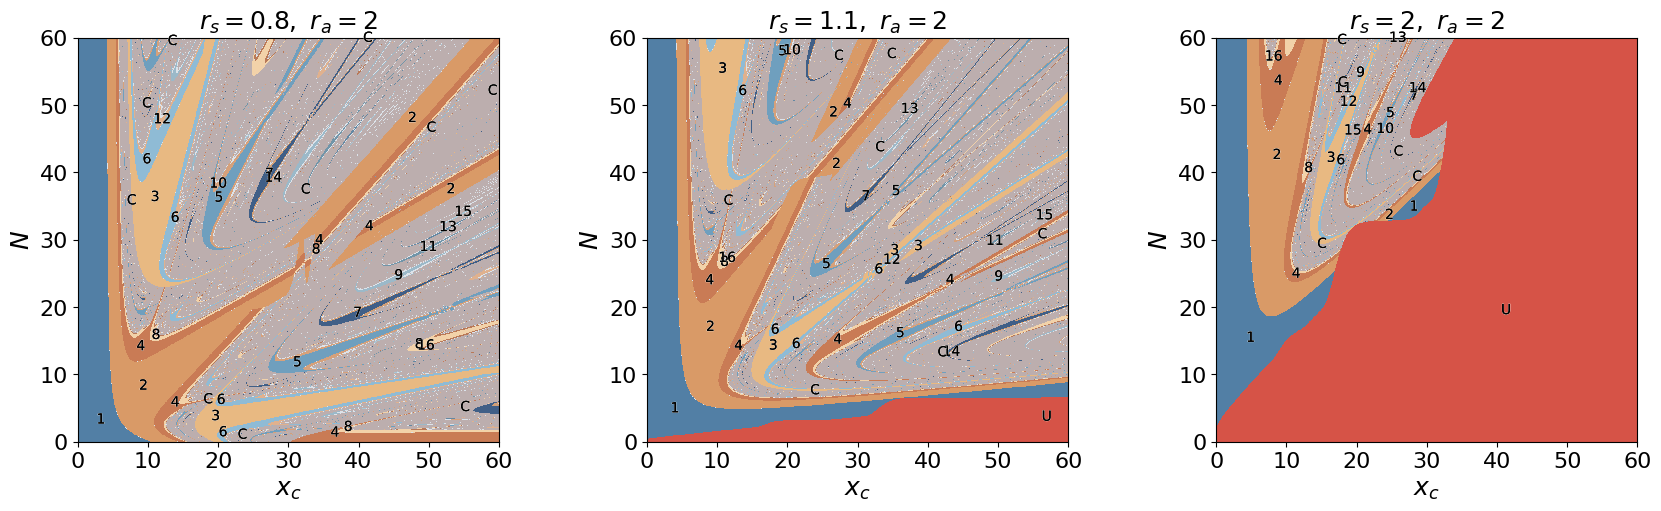

In [44]:
params = [(0.8, 2), (1.1, 2), (2, 2)]
resolution = 1300
fig, axes, results = plot_regime_maps_2(
    params=params,
    xc_range=(0, 60),
    N_range=(0, 60),
    resolution=resolution, 
    x0=0.0005,
    figsize=(16.5, 5),
    fontsize=18,
    min_label_area=round(200 * (resolution / 300) ** 2)
)

plt.show()

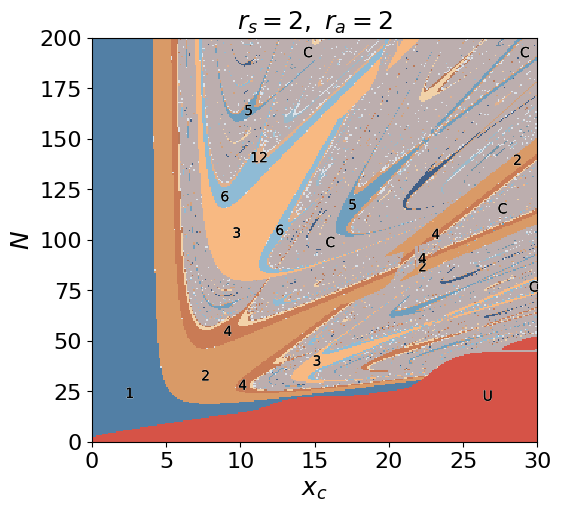

In [21]:
params = [(2, 2)]
resolution = 300
fig, axes, results = plot_regime_maps_2(
    params=params,
    xc_range=(0,30),
    N_range=(0, 200),
    resolution=resolution, 
    x0=0.7,
    figsize=(5.5, 5),
    fontsize=18,
    min_label_area=round(200 * (resolution / 300) ** 2)
)

plt.show()

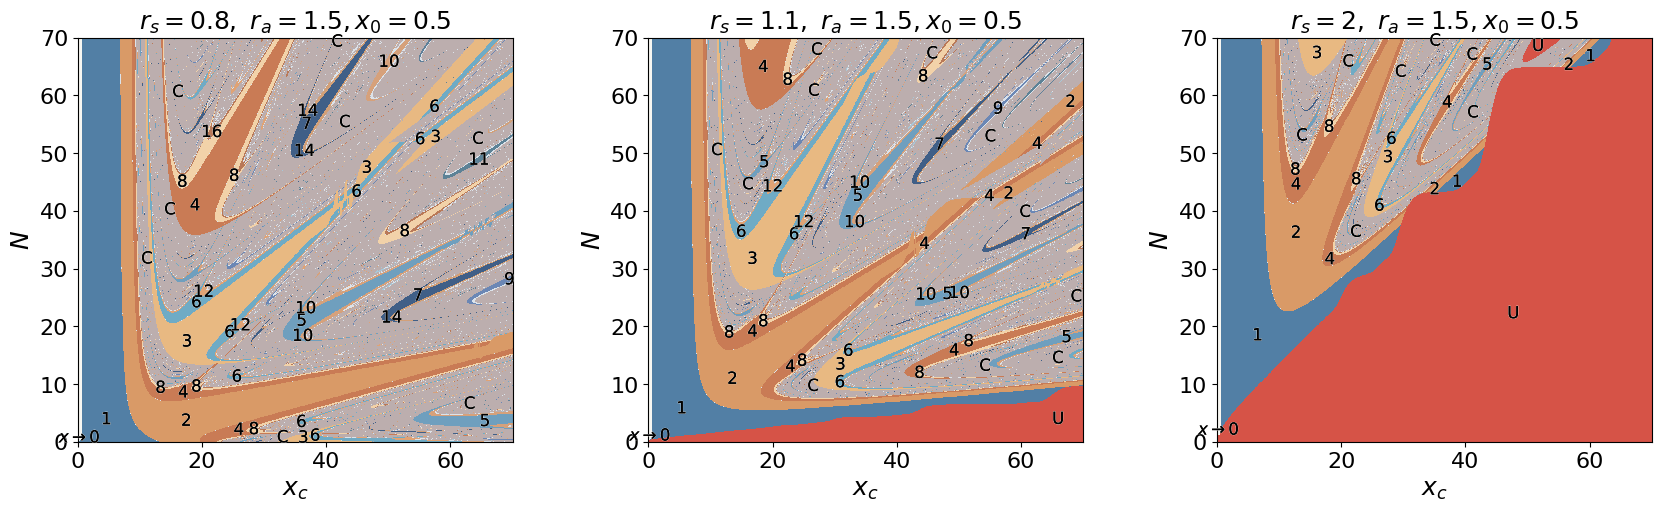

In [104]:
params = [(0.8, 1.5), (1.1, 1.5), (2, 1.5)]
resolution = 1300
fig, axes, results = plot_regime_maps_2(
    params=params,
    xc_range=(0, 70),
    N_range=(0, 70),
    resolution=resolution, 
    x0=0.5,
    figsize=(16.5, 5),
    fontsize=18,
    min_label_area=round(100 * (resolution / 300) ** 2)
)

plt.show()

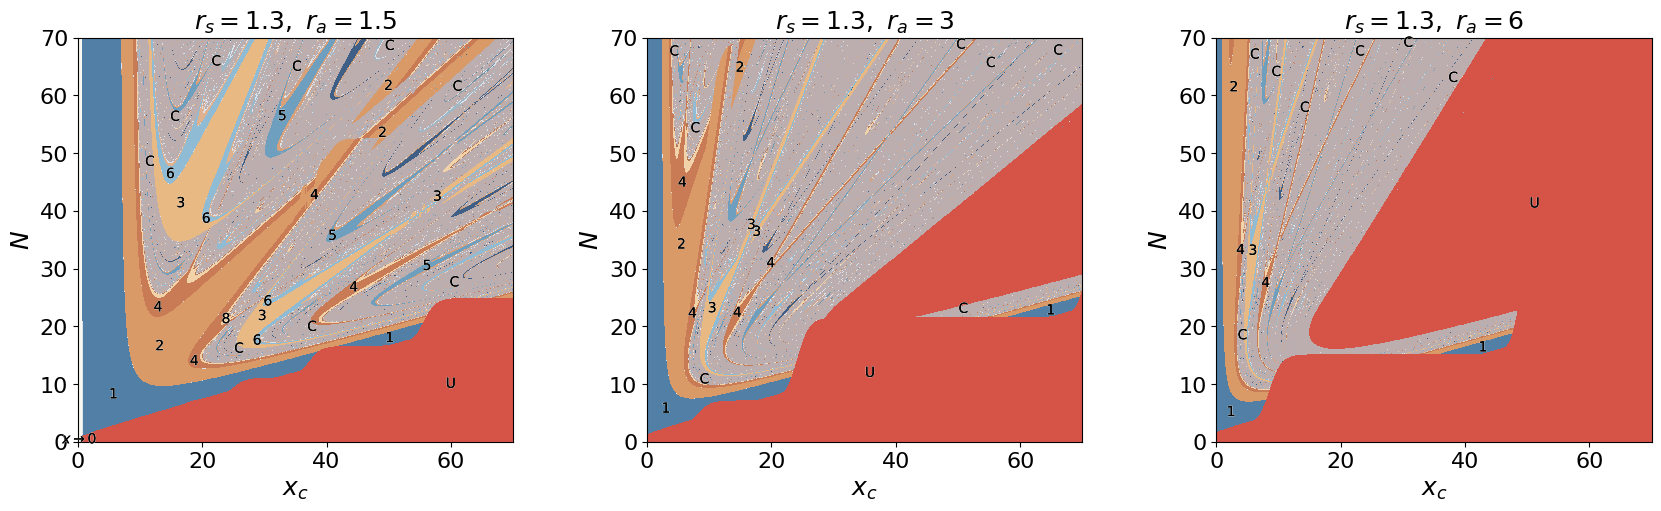

In [75]:
params = [(1.3, 1.5), (1.3, 3), (1.3, 6)]
resolution=1300
fig, axes, results = plot_regime_maps_2(
    params=params,
    xc_range=(0, 70),
    N_range=(0, 70),
    resolution=resolution, 
    x0=0.5,
    figsize=(16.5, 5),
    fontsize=18,
    min_label_area=round(200 * (resolution / 300) ** 2)
)

plt.show()

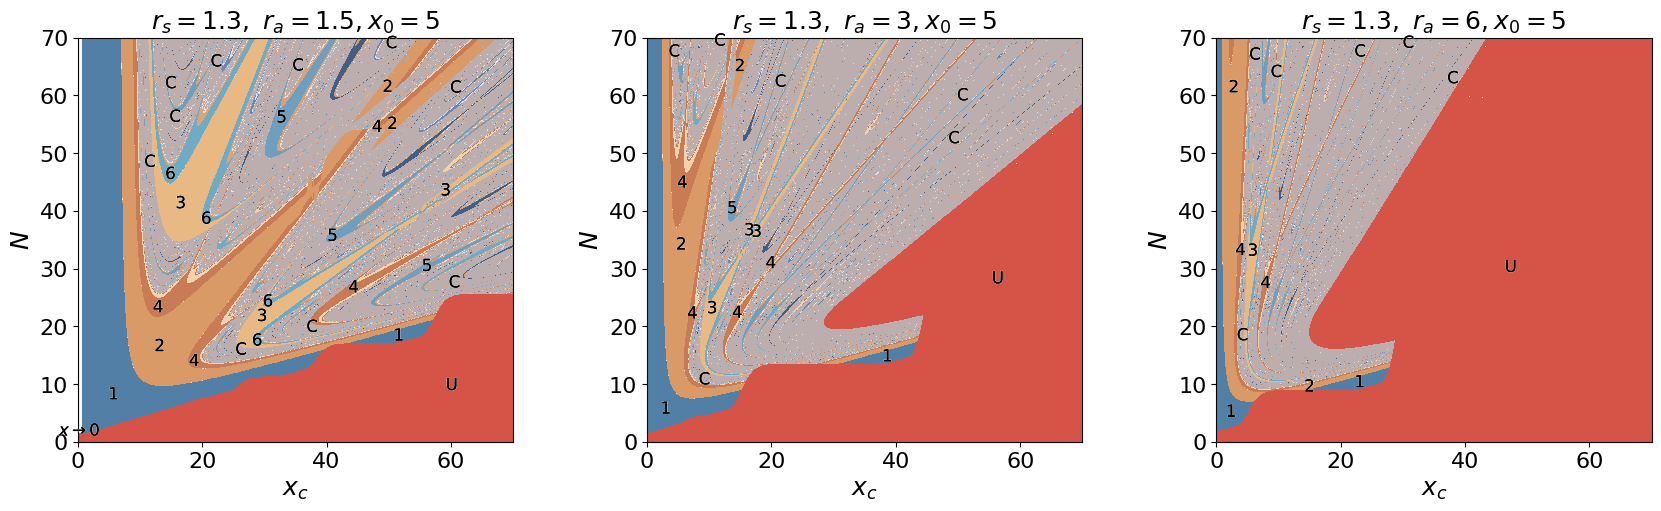

In [105]:
params = [(1.3, 1.5), (1.3, 3), (1.3, 6)]
resolution=1300
fig, axes, results = plot_regime_maps_2(
    params=params,
    xc_range=(0, 70),
    N_range=(0, 70),
    resolution=resolution, 
    x0=5,
    figsize=(16.5, 5),
    fontsize=18,
    min_label_area=round(200 * (resolution / 300) ** 2)
)

plt.show()

In [106]:
@njit(parallel=True)
def calculate_map_3(
    xc_values, x0_values,
    rs, ra, N,
    transient, tail_len, max_period,
    period_tol, extinction_tol, lyap_tol,
    escape_limit, escape_steps
):
    result = np.empty(
        (len(x0_values), len(xc_values)),
        dtype=np.int16
    )

    for i in prange(len(x0_values)):

        x0 = x0_values[i]

        for j in range(len(xc_values)):

            xc = xc_values[j]

            result[i, j] = calculate_point(
                rs, ra, xc, N, x0,
                transient, tail_len, max_period,
                period_tol, extinction_tol, lyap_tol,
                escape_limit, escape_steps
            )

    return result

def plot_regime_maps_3(
    params,
    xc_range=(0, 10),
    x0_range=(0, 10),
    resolution=400,
    N=1.0,
    transient=5000,
    tail_len=128,
    max_period=16,
    period_tol=1e-7,
    extinction_tol=1e-14,
    lyap_tol=1e-4,
    escape_limit=1e12,
    escape_steps=10,
    figsize=None,
    fontsize=9,
    min_label_area=100
):
    """
    Строит карты динамических режимов в один горизонтальный ряд.

    params = [(rs1, ra1), (rs2, ra2), ...]

    По горизонтали: x_c
    По вертикали:   x0

    Обозначения:
        x -> 0  — вымирание;
        1, 2, ... — периодические циклы;
        C — хаос;
        U — убегание на бесконечность.
    """

    n_maps = len(params)

    if n_maps == 0:
        raise ValueError(
            "Необходимо передать хотя бы одну пару (rs, ra)"
        )

    if max_period < 1:
        raise ValueError("max_period должен быть >= 1")

    if min_label_area < 1:
        raise ValueError("min_label_area должен быть >= 1")

    if resolution < 2:
        raise ValueError("resolution должен быть >= 2")

    if x0_range[0] < 0:
        raise ValueError("x0 должен быть >= 0")

    if x0_range[0] >= x0_range[1]:
        raise ValueError("x0_range задан некорректно")

    if xc_range[0] >= xc_range[1]:
        raise ValueError("xc_range задан некорректно")

    if figsize is None:
        figsize = (4 * n_maps, 3.5)

    # -------------------------------------------------
    # Сетка параметров
    # -------------------------------------------------
    xc_values = np.linspace(
        xc_range[0],
        xc_range[1],
        resolution
    )

    x0_values = np.linspace(
        x0_range[0],
        x0_range[1],
        resolution
    )

    tail_len = max(tail_len, 2 * max_period)

    if N <= 0:
        raise ValueError("N должно быть > 0")

    # -------------------------------------------------
    # Расчёт карт динамических режимов
    # -------------------------------------------------
    results = []

    for rs, ra in params:

        result = calculate_map_3(
            xc_values,
            x0_values,
            rs,
            ra,
            N,
            transient,
            tail_len,
            max_period,
            period_tol,
            extinction_tol,
            lyap_tol,
            escape_limit,
            escape_steps
        )

        results.append(result)

    # -------------------------------------------------
    # Цвета динамических режимов
    # -------------------------------------------------

    # Вымирание
    base_colors = ["#F8F7F2"]

    # Чередование холодных и тёплых оттенков.
    # Индекс соответствует периоду цикла.
    period_colors = [
        "#527FA5",  # 1 — холодный синий
        "#D99A67",  # 2 — тёплый охристый
        "#E8B982",  # 3 — светло-синий
        "#C97B55",  # 4 — терракотовый
        "#6F9FBE",  # 5 — голубой
        "#6fabc5",  # 6 — песочный
        "#405F87",  # 7 — глубокий синий
        "#F2D2A9",  # 8 — светлый тёплый
        "#6b87b5",  # 9 — серо-голубой
        "#D6A17B",  # 10 — приглушённый персиковый
        "#5d8296",  # 11 — стальной голубой
        "#e0a375",  # 12 — мягкий абрикосовый
        "#5f8099",  # 13 — сине-серый
        "#D2A078",  # 14 — тёплый бежево-коричневый
        "#A6C8D9",  # 15 — светлый холодный
        "#B97958",  # 16 — приглушённая терракота
    ]

    # Если max_period больше 16, продолжаем чередование.
    while len(period_colors) < max_period:
        period_colors.append(
            "#7195A9" if len(period_colors) % 2 == 0
            else "#D6A17B"
        )

    base_colors.extend(period_colors[:max_period])

    base_colors.extend([
        "#bcaeae",  # Хаос
        "#D65347",  # Убегание
        "#DCE3EA"   # Период > max_period
    ])

    cmap = ListedColormap(base_colors)

    boundaries = np.arange(
        -0.5,
        max_period + 4.5,
        1
    )

    norm = BoundaryNorm(
        boundaries,
        cmap.N
    )

    # -------------------------------------------------
    # Подписи динамических режимов
    # -------------------------------------------------
    def add_region_labels(ax, result):

        regimes = [
            (0, r"$x\to0$", "#626A73")
        ]

        # Периодические циклы
        for period in range(1, max_period + 1):
            regimes.append(
                (period, str(period), "#343943")
            )

        # Хаос
        regimes.append(
            (max_period + 1, "C", "#626A73")
        )

        # Убегание на бесконечность
        regimes.append(
            (max_period + 2, "U", "#7A2E16")
        )

        height, width = result.shape

        for code, label, text_color in regimes:

            mask = result == code

            if not np.any(mask):
                continue

            # Выделяем связные области одного режима.
            # Соседство по диагонали тоже учитывается.
            components, n_components = ndi.label(
                mask,
                structure=np.ones((3, 3), dtype=np.uint8)
            )

            if n_components == 0:
                continue

            slices = ndi.find_objects(components)
            component_info = []

            for component_id, slc in enumerate(
                slices, start=1
            ):

                if slc is None:
                    continue

                local_component = (
                    components[slc] == component_id
                )

                area = int(local_component.sum())

                component_info.append(
                    (area, component_id, slc, local_component)
                )

            # Подписываем все достаточно крупные области.
            # Если таких нет, подписываем крупнейшую.
            selected = [
                item for item in component_info
                if item[0] >= min_label_area
            ]

            if not selected and component_info:
                selected = [
                    max(
                        component_info,
                        key=lambda item: item[0]
                    )
                ]

            for area, component_id, slc, local_component in selected:

                # Ищем точку внутри области,
                # максимально удалённую от её границы.
                padded = np.pad(
                    local_component,
                    1,
                    mode="constant",
                    constant_values=False
                )

                distances = ndi.distance_transform_edt(padded)

                row, col = np.unravel_index(
                    np.argmax(distances),
                    distances.shape
                )

                row = row - 1 + slc[0].start
                col = col - 1 + slc[1].start

                # Перевод индексов в координаты параметров.
                # Столбцы соответствуют x_c.
                # Строки соответствуют N.
                xc = (
                    xc_range[0]
                    + (col + 0.5)
                    * (xc_range[1] - xc_range[0]) / width
                )

                x0 = (
                    x0_range[0]
                    + (row + 0.5)
                    * (x0_range[1] - x0_range[0]) / height
                )

                label_size = max(7, fontsize - 8)

                ax.text(
                    xc,
                    x0,
                    label,
                    ha="center",
                    va="center",
                    fontsize=label_size,
                    color="black",
                    zorder=5,
                    bbox=dict(
                        boxstyle="square,pad=2.5",
                        facecolor="none",
                        edgecolor="none"
                    ),
                    path_effects=[
                        pe.withStroke(
                            linewidth=0.5,
                            foreground="#F8F7F2"
                        ),
                        pe.Normal()
                    ]
                )

    # -------------------------------------------------
    # Построение карт
    # -------------------------------------------------
    fig = plt.figure(
        figsize=figsize,
        constrained_layout=True
    )

    gs = fig.add_gridspec(
        1,
        n_maps,
        wspace=0.12
    )
    
    axes = [
        fig.add_subplot(gs[0, i])
        for i in range(n_maps)
    ]

    for ax, result, (rs, ra) in zip(
        axes,
        results,
        params
    ):

        ax.imshow(
            result,
            origin="lower",
            extent=[
                xc_range[0],
                xc_range[1],
                x0_range[0],
                x0_range[1]
            ],
            aspect="auto",
            cmap=cmap,
            norm=norm,
            interpolation="nearest"
        )

        # Подписи периодов и остальных режимов
        add_region_labels(ax, result)

        ax.set_xlabel(
            r"$x_c$",
            fontsize=fontsize
        )

        ax.set_ylabel(
            r"$x_0$",
            fontsize=fontsize
        )

        ax.set_title(
            rf"$r_s={rs},\ r_a={ra},\ N={N}$",
            fontsize=fontsize
        )

        ax.tick_params(
            labelsize=max(6, fontsize - 2)
        )

    # Colorbar намеренно отсутствует.

    return fig, axes, results

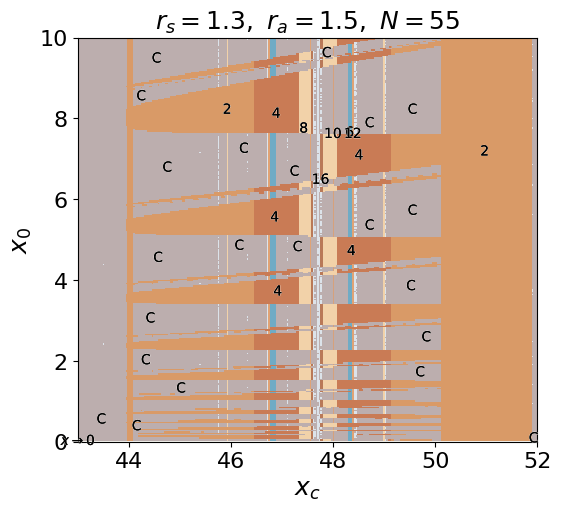

In [118]:
params = [(1.3, 1.5)]
resolution=300
fig, axes, results = plot_regime_maps_3(
    params=params,
    xc_range=(43, 52),
    x0_range=(0, 10),
    resolution=resolution, 
    N=55,
    figsize=(5.5, 5),
    fontsize=18,
    min_label_area=round(500 * (resolution / 300) ** 2)
)

plt.show()

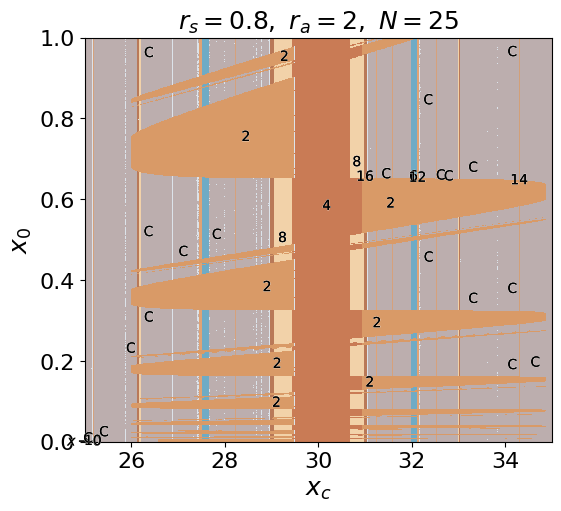

In [108]:
params = [(0.8, 2)]
resolution=1300
fig, axes, results = plot_regime_maps_3(
    params=params,
    xc_range=(25, 35),
    x0_range=(0, 1),
    resolution=resolution, 
    N=25,
    figsize=(5.5, 5),
    fontsize=18,
    min_label_area=round(500 * (resolution / 300) ** 2)
)

plt.show()

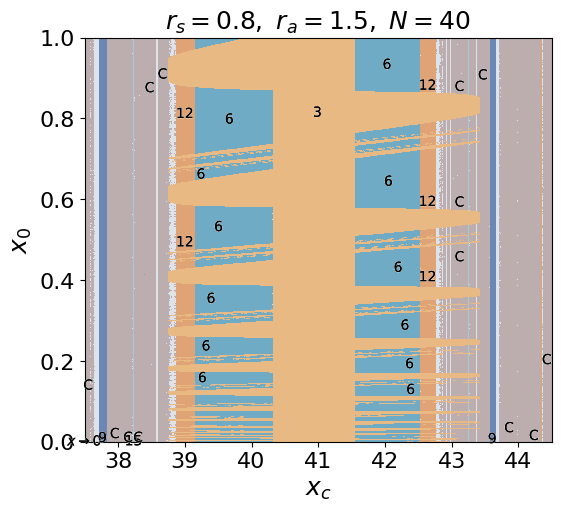

In [109]:
params = [(0.8, 1.5)]
resolution=1300
fig, axes, results = plot_regime_maps_3(
    params=params,
    xc_range=(37.5, 44.5),
    x0_range=(0, 1),
    resolution=resolution, 
    N=40,
    figsize=(5.5, 5),
    fontsize=18,
    min_label_area=round(300 * (resolution / 300) ** 2)
)

plt.show()

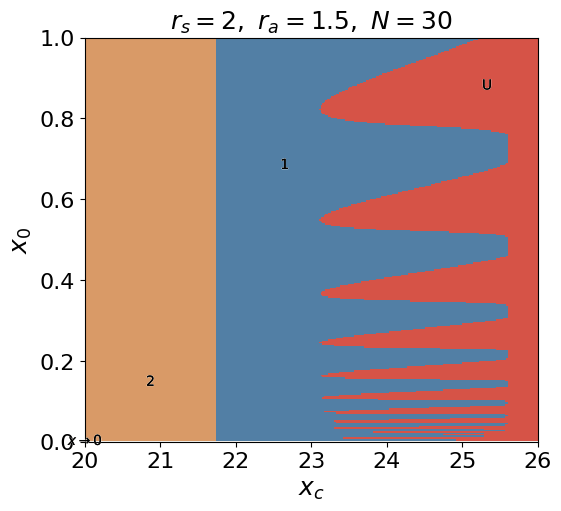

In [23]:
params = [(2, 1.5)]
resolution=300
fig, axes, results = plot_regime_maps_3(
    params=params,
    xc_range=(20, 26),
    x0_range=(0, 1),
    resolution=resolution, 
    N=30,
    figsize=(5.5, 5),
    fontsize=18,
    min_label_area=round(300 * (resolution / 300) ** 2)
)

plt.show()

In [20]:
def f(x, xc):
    return 1.0 / (1.0 + np.exp(xc - x))
def m(x, N):
    return x / (N + x)
def Xn(x, r_s, r_a, N, xc = 5):
    F = f(x, xc)
    M = m(x, N)
    return ((1 - F) * r_a + F * M * r_s) * x

def r_tragectory(ax, xc_val, N_val, r_s_val, r_a_val, x0):
    N0 = N_val
    xc = xc_val
    r_s = r_s_val
    r_a = r_a_val
    R = []
    X = []
    x = x0
    for n in range(5000):
        x = Xn(x, r_s, r_a, N0, xc)
        R.append(n)
        X.append(x)
    ax.plot(R[-200:], X[-200:], ls='', marker='.')
    ax.set_title(f'x_c = {xc_val}, N = {N_val}, r_s = {r_s_val}, r_a = {r_a_val}, x_start = {x0}', fontsize=10)
    ax.set_xlabel('$n$')
    ax.set_ylabel('$x_n$')

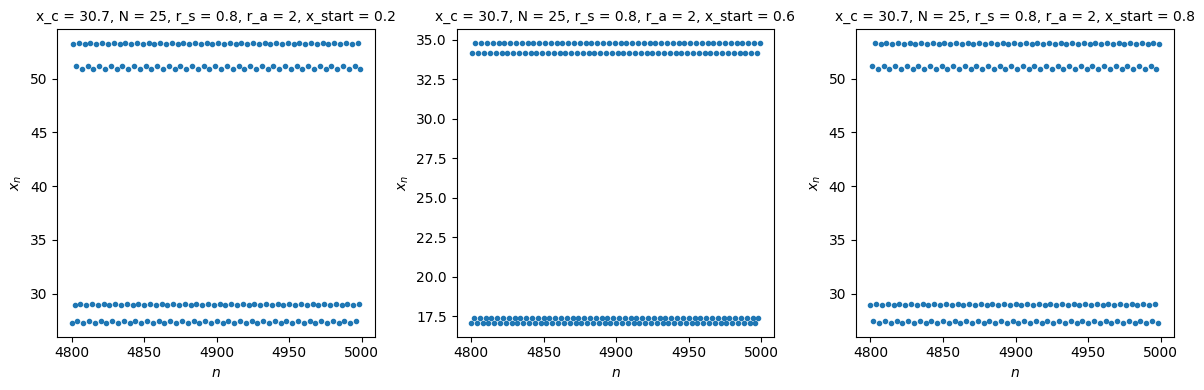

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
x0_values = [0.2, 0.6, 0.8]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 30.7, 25, 0.8, 2, x0)

plt.tight_layout()
plt.show()

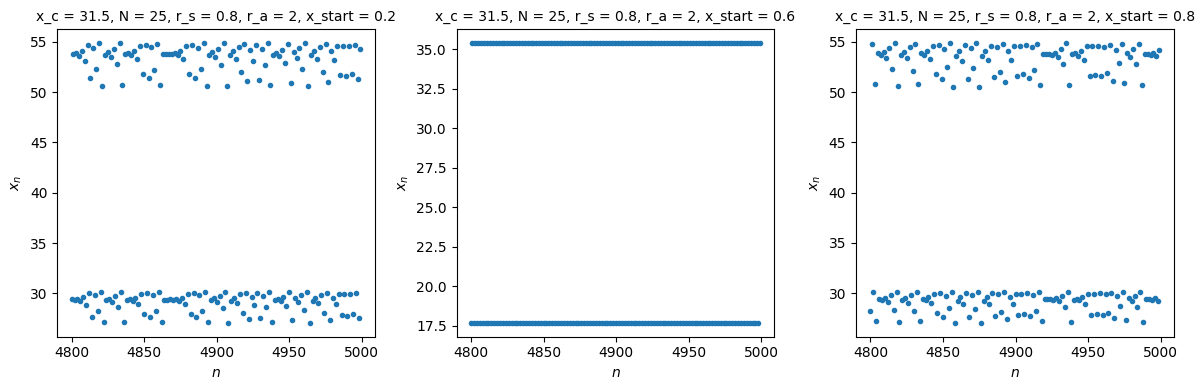

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
x0_values = [0.2, 0.6, 0.8]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 31.5, 25, 0.8, 2, x0)

plt.tight_layout()
plt.show()

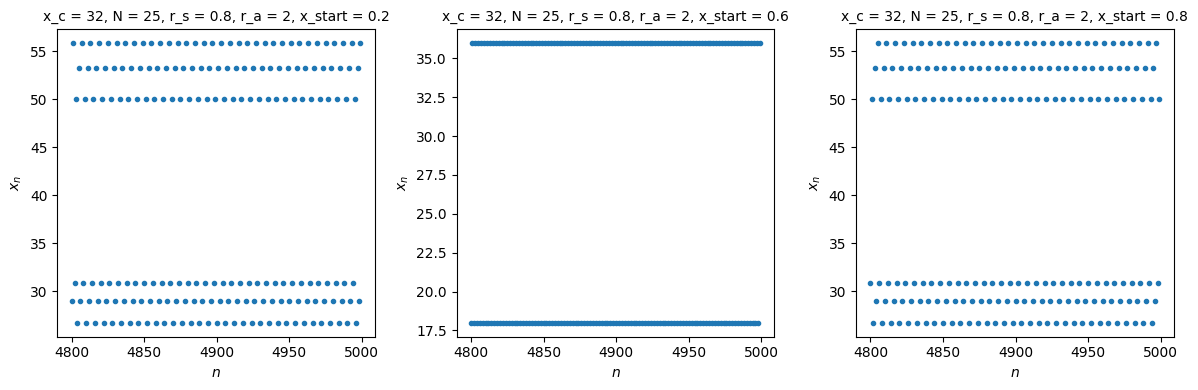

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
x0_values = [0.2, 0.6, 0.8]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 32, 25, 0.8, 2, x0)

plt.tight_layout()
plt.show()